# Experiment 9: Hybrid BiLSTM + MLP Model

## Overview
- Model: Hybrid architecture combining BiLSTM (text) and MLP (structured + engineered + TF-IDF features)
- Architecture:
  - **BiLSTM branch**: Word embedding (100) → Bidirectional LSTM (64 units) → Dropout(0.3) → Dense(128)
  - **MLP branch**: All features (structured + TF-IDF/pooled) → Dense(128) → BatchNorm → Dropout(0.3)
  - **Fusion**: Concat → Dense(256) → Dropout(0.4) → Dense(1, sigmoid)
- Training: Adam (lr=1e-3), batch_size=256, max_epochs=20, early_stopping (patience=3)
- Approach: Train with Stratified 5-Fold CV, save per-fold models and metrics
- Artifacts: model files, tokenizer, preprocessor, metrics.json, and submission CSV

In [1]:
# %pip install tensorflow scikit-learn

In [2]:
use_drive = False

# uncomment if running on colab
# from google.colab import drive
# drive.mount('/content/drive')
# use_drive = True

In [3]:
# Hybrid model imports
import os
import json
import pickle
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, log_loss
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, Model, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras import mixed_precision

In [4]:
# Initialize paths
DATA_PATH = 'data/'
EXPERIMENT_PATH = 'experiments/'

if use_drive:
    DRIVE_PATH = '/content/drive/MyDrive/Kaggle'
    EXPERIMENT_PATH = os.path.join(DRIVE_PATH, EXPERIMENT_PATH)
    # Enable mixed precision for faster training on GPU
    policy = mixed_precision.Policy('mixed_float16')
    mixed_precision.set_global_policy(policy)
    print('Mixed precision enabled (GPU acceleration)')

EXPERIMENT_NAME = 'exp_9_hybrid_bilstm_mlp'
EXPERIMENT_DIR = os.path.join(EXPERIMENT_PATH, EXPERIMENT_NAME)
os.makedirs(EXPERIMENT_DIR, exist_ok=True)
os.makedirs(os.path.join(EXPERIMENT_DIR, 'models'), exist_ok=True)
print('Experiment directory:', EXPERIMENT_DIR)

Experiment directory: experiments/exp_9_hybrid_bilstm_mlp


In [5]:
# Load data - use structured features for MLP branch
train = pd.read_csv(os.path.join(DATA_PATH, 'train_w_struct.csv'))
test = pd.read_csv(os.path.join(DATA_PATH, 'test_w_struct.csv'))

print(f'Train shape: {train.shape}')
print(f'Test shape: {test.shape}')
print(f'\nTrain columns: {train.columns.tolist()}')

Train shape: (4712, 36)
Test shape: (1178, 35)

Train columns: ['id', 'text', 'label', 'char_len', 'word_count', 'unique_word_count', 'type_token_ratio', 'sentence_count', 'avg_sentence_length', 'punctuation_count', 'punctuation_ratio', 'uppercase_count', 'uppercase_ratio', 'stopword_count', 'stopword_ratio', 'flesch_reading_ease', 'flesch_kincaid_grade', 'shannon_entropy', 'pos_adj', 'pos_adp', 'pos_adv', 'pos_aux', 'pos_cconj', 'pos_det', 'pos_intj', 'pos_noun', 'pos_num', 'pos_part', 'pos_pron', 'pos_propn', 'pos_punct', 'pos_sconj', 'pos_sym', 'pos_verb', 'pos_x', 'pos_space']


In [6]:
# Prepare word-level tokenizer for BiLSTM branch
texts = train['text'].astype(str).values
test_texts = test['text'].astype(str).values
labels = train['label'].values

# Tokenizer at word level
word_tokenizer = Tokenizer(num_words=20000, lower=True, oov_token='<OOV>')
word_tokenizer.fit_on_texts(texts)
vocab_size = min(len(word_tokenizer.word_index) + 1, 20000)
print(f'Word vocab size: {vocab_size}')

# Save tokenizer mapping
tokenizer_path = os.path.join(EXPERIMENT_DIR, 'tokenizer.json')
with open(tokenizer_path, 'w') as f:
    json.dump({'word_index': word_tokenizer.word_index, 'num_words': 20000}, f)
print('Saved tokenizer to', tokenizer_path)

Word vocab size: 17519
Saved tokenizer to experiments/exp_9_hybrid_bilstm_mlp/tokenizer.json


In [7]:
# Convert texts to sequences and pad for BiLSTM branch
MAXLEN = 200
X_word_seq = word_tokenizer.texts_to_sequences(texts)
X_test_word_seq = word_tokenizer.texts_to_sequences(test_texts)
X_word_pad = pad_sequences(X_word_seq, maxlen=MAXLEN, padding='post', truncating='post')
X_test_word_pad = pad_sequences(X_test_word_seq, maxlen=MAXLEN, padding='post', truncating='post')
print('BiLSTM input - Train shape:', X_word_pad.shape)
print('BiLSTM input - Test shape:', X_test_word_pad.shape)

BiLSTM input - Train shape: (4712, 200)
BiLSTM input - Test shape: (1178, 200)


In [8]:
# Prepare MLP branch features (structured + TF-IDF)
# Define columns
target_col = 'label'
id_col = 'id'
text_col = 'text'

# Prepare features for MLP branch
X_mlp = train.drop([id_col, target_col], axis=1)
X_test_mlp = test.drop([id_col], axis=1)
test_ids = test[id_col].values

# Get numeric (structured) columns
numeric_cols = [col for col in X_mlp.columns if col != text_col]
print(f'MLP branch - Numeric features: {len(numeric_cols)}')
print(f'MLP branch - Text feature: {text_col}')

# TF-IDF + SVD parameters for MLP text features
vectorizer_params = {
    'max_features': 20000,
    'ngram_range': (1, 2),
    'min_df': 2,
    'max_df': 0.95
}
svd_n_components = 100

print(f'Total MLP features: {svd_n_components + len(numeric_cols)}')

MLP branch - Numeric features: 33
MLP branch - Text feature: text
Total MLP features: 133


In [9]:
# Hybrid model builder
def build_hybrid_model(vocab_size, maxlen, n_mlp_features, embedding_dim=100, lstm_units=64):
    """
    Build hybrid BiLSTM + MLP model
    
    BiLSTM branch: word embedding → Bidirectional LSTM → Dense(128)
    MLP branch: structured features → Dense(128) → BatchNorm → Dropout(0.3)
    Fusion: Concat → Dense(256) → Dropout(0.4) → Dense(1, sigmoid)
    """
    # BiLSTM branch
    lstm_input = Input(shape=(maxlen,), name='lstm_input')
    x = layers.Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=maxlen, mask_zero=True)(lstm_input)
    x = layers.Bidirectional(layers.LSTM(lstm_units, return_sequences=False))(x)
    x = layers.Dropout(0.3)(x)
    lstm_branch = layers.Dense(128, activation='relu', name='lstm_dense')(x)
    lstm_branch = layers.Dropout(0.2)(lstm_branch)
    
    # MLP branch (all features: structured + TF-IDF)
    mlp_input = Input(shape=(n_mlp_features,), name='mlp_input')
    m = layers.Dense(128, activation='relu', name='mlp_dense')(mlp_input)
    m = layers.BatchNormalization()(m)
    mlp_branch = layers.Dropout(0.3)(m)
    
    # Fusion layer
    combined = layers.Concatenate()([lstm_branch, mlp_branch])
    z = layers.Dense(256, activation='relu', name='fusion_dense')(combined)
    z = layers.Dropout(0.4)(z)
    output = layers.Dense(1, activation='sigmoid', name='output', dtype='float32')(z)
    
    model = Model(inputs=[lstm_input, mlp_input], outputs=output)
    
    # Compile with Adam optimizer (lr=1e-3)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3, weight_decay=1e-5),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='auc'), 'accuracy']
    )
    
    return model

# Quick sanity check
model = build_hybrid_model(vocab_size, MAXLEN, svd_n_components + len(numeric_cols))
model.summary()

/Users/winston/Documents/School/Y3S1/BT4012/Kaggle/Competition 2/.venv/lib/python3.13/site-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lstm_input          │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 200, 100)  │  1,751,900 │ lstm_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 200)       │          0 │ lstm_input[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     84,480 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_input           │ (None, 133)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_dense (Dense)   │ (None, 128)       │     17,152 │ mlp_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_dense (Dense)  │ (None, 128)       │     16,512 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128)       │        512 │ mlp_dense[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ lstm_dense[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256)       │          0 │ dropout_1[0][0],  │
│ (Concatenate)       │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dense        │ (None, 256)       │     65,792 │ concatenate[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 256)       │          0 │ fusion_dense[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 1)         │        257 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,936,605 (7.39 MB)

 Trainable params: 1,936,349 (7.39 MB)

 Non-trainable params: 256 (1.00 KB)

In [10]:
# Cross-validation setup
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

fold_metrics = []
fold_predictions = np.zeros(len(test))

print(f'Starting 5-fold CV with Hybrid BiLSTM + MLP...')
print(f'BiLSTM: embedding_dim={100}, lstm_units={64}, maxlen={MAXLEN}')
print(f'MLP: {svd_n_components} TF-IDF components + {len(numeric_cols)} structured features')
print('='*60)

Starting 5-fold CV with Hybrid BiLSTM + MLP...
BiLSTM: embedding_dim=100, lstm_units=64, maxlen=200
MLP: 100 TF-IDF components + 33 structured features


In [11]:
# Cross-validation training loop
for fold, (train_idx, val_idx) in enumerate(skf.split(X_word_pad, labels), 1):
    print(f'\n=== Fold {fold}/{n_folds} ===')
    
    # Split BiLSTM data
    X_lstm_tr, X_lstm_val = X_word_pad[train_idx], X_word_pad[val_idx]
    y_tr, y_val = labels[train_idx], labels[val_idx]
    
    # Split and preprocess MLP data
    X_mlp_tr, X_mlp_val = X_mlp.iloc[train_idx].reset_index(drop=True), X_mlp.iloc[val_idx].reset_index(drop=True)
    
    # Build MLP preprocessing pipeline (TF-IDF + SVD for text, imputation for numeric)
    text_pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(**vectorizer_params)),
        ('svd', TruncatedSVD(n_components=svd_n_components, random_state=42))
    ])
    
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median'))
    ])
    
    preprocessor = ColumnTransformer([
        ('text', text_pipeline, text_col),
        ('numeric', numeric_pipeline, numeric_cols)
    ])
    
    # Fit preprocessor and transform data
    print('Preprocessing MLP features...', end=' ')
    X_mlp_tr_processed = preprocessor.fit_transform(X_mlp_tr)
    X_mlp_val_processed = preprocessor.transform(X_mlp_val)
    X_test_mlp_processed = preprocessor.transform(X_test_mlp)
    
    # Scale MLP features
    scaler = StandardScaler()
    X_mlp_tr_scaled = scaler.fit_transform(X_mlp_tr_processed)
    X_mlp_val_scaled = scaler.transform(X_mlp_val_processed)
    X_test_mlp_scaled = scaler.transform(X_test_mlp_processed)
    print('Done')
    
    # Build model
    n_mlp_features = X_mlp_tr_scaled.shape[1]
    model = build_hybrid_model(vocab_size, MAXLEN, n_mlp_features, embedding_dim=100, lstm_units=64)
    
    # Model path
    model_path = os.path.join(EXPERIMENT_DIR, 'models', f'model_fold_{fold}.keras')
    preprocessor_path = os.path.join(EXPERIMENT_DIR, 'models', f'preprocessor_fold_{fold}.pkl')
    
    # Callbacks
    cb = [
        callbacks.EarlyStopping(
            monitor='val_auc', 
            patience=3, 
            restore_best_weights=True,
            mode='max',
            verbose=1
        ),
        callbacks.ModelCheckpoint(
            model_path, 
            monitor='val_auc', 
            save_best_only=True,
            mode='max',
            verbose=0
        ),
        callbacks.ReduceLROnPlateau(
            monitor='val_auc',
            factor=0.5,
            patience=2,
            mode='max',
            verbose=1
        )
    ]
    
    # Train model
    print('Training hybrid model...')
    history = model.fit(
        [X_lstm_tr, X_mlp_tr_scaled],
        y_tr,
        validation_data=([X_lstm_val, X_mlp_val_scaled], y_val),
        epochs=20,
        batch_size=256,
        callbacks=cb,
        verbose=1
    )
    
    # Save preprocessor
    with open(preprocessor_path, 'wb') as f:
        pickle.dump({'preprocessor': preprocessor, 'scaler': scaler}, f)
    print(f'Saved preprocessor to {preprocessor_path}')
    
    # Validation predictions
    y_val_proba = model.predict([X_lstm_val, X_mlp_val_scaled], batch_size=256).ravel()
    y_val_proba = np.clip(y_val_proba, 1e-6, 1-1e-6)  # Clip for safe logit operations
    y_val_pred = (y_val_proba >= 0.5).astype(int)
    
    # Calculate metrics
    metrics = {
        'fold': int(fold),
        'accuracy': float(accuracy_score(y_val, y_val_pred)),
        'precision': float(precision_score(y_val, y_val_pred, zero_division=0)),
        'recall': float(recall_score(y_val, y_val_pred, zero_division=0)),
        'f1': float(f1_score(y_val, y_val_pred, zero_division=0)),
        'roc_auc': float(roc_auc_score(y_val, y_val_proba)),
        'log_loss': float(log_loss(y_val, y_val_proba)),
        'train_size': int(len(train_idx)),
        'val_size': int(len(val_idx)),
        'best_epoch': int(np.argmax(history.history['val_auc']) + 1)
    }
    fold_metrics.append(metrics)
    print(f'Fold {fold} metrics - ROC AUC: {metrics["roc_auc"]:.5f}, Log Loss: {metrics["log_loss"]:.5f}')
    
    # Test predictions (load best model)
    best_model = keras.models.load_model(model_path)
    test_proba = best_model.predict([X_test_word_pad, X_test_mlp_scaled], batch_size=256).ravel()
    test_proba = np.clip(test_proba, 1e-6, 1-1e-6)
    fold_predictions += test_proba / n_folds
    
    print(f'Model for fold {fold} saved to {model_path}')

print('\n' + '='*60)
print('Cross-validation complete!')
print('='*60)


=== Fold 1/5 ===
Preprocessing MLP features... Done
Training hybrid model...
Epoch 1/20
Done
Training hybrid model...
Epoch 1/20


/Users/winston/Documents/School/Y3S1/BT4012/Kaggle/Competition 2/.venv/lib/python3.13/site-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 421ms/step - accuracy: 0.7318 - auc: 0.7774 - loss: 0.5209 - val_accuracy: 0.7656 - val_auc: 0.9172 - val_loss: 0.4336 - learning_rate: 0.0010
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 421ms/step - accuracy: 0.7318 - auc: 0.7774 - loss: 0.5209 - val_accuracy: 0.7656 - val_auc: 0.9172 - val_loss: 0.4336 - learning_rate: 0.0010
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 394ms/step - accuracy: 0.8864 - auc: 0.9481 - loss: 0.2720 - val_accuracy: 0.8770 - val_auc: 0.9760 - val_loss: 0.2698 - learning_rate: 0.0010
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 394ms/step - accuracy: 0.8864 - auc: 0.9481 - loss: 0.2720 - val_accuracy: 0.8770 - val_auc: 0.9760 - val_loss: 0.2698 - learning_rate: 0.0010
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 396ms/step - accuracy: 0.9536 - auc: 0.9910 - loss: 0.1185 - val_accuracy: 0.9268 - val_auc: 0.9871 - val_loss: 0.2060 - learning_rate: 0.0010
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 396ms/step - accuracy: 0.9536 - auc: 0.9910 - lo

/Users/winston/Documents/School/Y3S1/BT4012/Kaggle/Competition 2/.venv/lib/python3.13/site-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 446ms/step - accuracy: 0.7304 - auc: 0.7761 - loss: 0.5248 - val_accuracy: 0.7359 - val_auc: 0.9430 - val_loss: 0.4322 - learning_rate: 0.0010
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 446ms/step - accuracy: 0.7304 - auc: 0.7761 - loss: 0.5248 - val_accuracy: 0.7359 - val_auc: 0.9430 - val_loss: 0.4322 - learning_rate: 0.0010
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 444ms/step - accuracy: 0.9040 - auc: 0.9587 - loss: 0.2474 - val_accuracy: 0.8908 - val_auc: 0.9835 - val_loss: 0.2493 - learning_rate: 0.0010
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 444ms/step - accuracy: 0.9040 - auc: 0.9587 - loss: 0.2474 - val_accuracy: 0.8908 - val_auc: 0.9835 - val_loss: 0.2493 - learning_rate: 0.0010
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 409ms/step - accuracy: 0.9583 - auc: 0.9921 - loss: 0.1084 - val_accuracy: 0.9236 - val_auc: 0.9903 - val_loss: 0.1997 - learning_rate: 0.0010
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 409ms/step - accuracy: 0.9583 - auc: 0.9921 - lo

...

15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 386ms/step - accuracy: 0.6650 - auc: 0.7074 - loss: 0.6007 - val_accuracy: 0.7155 - val_auc: 0.9266 - val_loss: 0.4679 - learning_rate: 0.0010
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 386ms/step - accuracy: 0.6650 - auc: 0.7074 - loss: 0.6007 - val_accuracy: 0.7155 - val_auc: 0.9266 - val_loss: 0.4679 - learning_rate: 0.0010
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 356ms/step - accuracy: 0.8814 - auc: 0.9393 - loss: 0.2978 - val_accuracy: 0.8429 - val_auc: 0.9776 - val_loss: 0.3359 - learning_rate: 0.0010
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 356ms/step - accuracy: 0.8814 - auc: 0.9393 - loss: 0.2978 - val_accuracy: 0.8429 - val_auc: 0.9776 - val_loss: 0.3359 - learning_rate: 0.0010
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 357ms/step - accuracy: 0.9491 - auc: 0.9868 - loss: 0.1396 - val_accuracy: 0.9225 - val_auc: 0.9841 - val_loss: 0.2057 - learning_rate: 0.0010
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 357ms/step - accuracy: 0.9491 - auc: 0.9868 - lo

/Users/winston/Documents/School/Y3S1/BT4012/Kaggle/Competition 2/.venv/lib/python3.13/site-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 378ms/step - accuracy: 0.7186 - auc: 0.7638 - loss: 0.5347 - val_accuracy: 0.8163 - val_auc: 0.9540 - val_loss: 0.3754 - learning_rate: 0.0010
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 378ms/step - accuracy: 0.7186 - auc: 0.7638 - loss: 0.5347 - val_accuracy: 0.8163 - val_auc: 0.9540 - val_loss: 0.3754 - learning_rate: 0.0010
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 348ms/step - accuracy: 0.8944 - auc: 0.9544 - loss: 0.2565 - val_accuracy: 0.9384 - val_auc: 0.9875 - val_loss: 0.1977 - learning_rate: 0.0010
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 348ms/step - accuracy: 0.8944 - auc: 0.9544 - loss: 0.2565 - val_accuracy: 0.9384 - val_auc: 0.9875 - val_loss: 0.1977 - learning_rate: 0.0010
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 355ms/step - accuracy: 0.9565 - auc: 0.9919 - loss: 0.1110 - val_accuracy: 0.9639 - val_auc: 0.9945 - val_loss: 0.1056 - learning_rate: 0.0010
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 355ms/step - accuracy: 0.9565 - auc: 0.9919 - lo

/Users/winston/Documents/School/Y3S1/BT4012/Kaggle/Competition 2/.venv/lib/python3.13/site-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 387ms/step - accuracy: 0.7424 - auc: 0.7848 - loss: 0.5088 - val_accuracy: 0.7781 - val_auc: 0.9337 - val_loss: 0.4147 - learning_rate: 0.0010
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 387ms/step - accuracy: 0.7424 - auc: 0.7848 - loss: 0.5088 - val_accuracy: 0.7781 - val_auc: 0.9337 - val_loss: 0.4147 - learning_rate: 0.0010
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 349ms/step - accuracy: 0.8958 - auc: 0.9552 - loss: 0.2569 - val_accuracy: 0.9172 - val_auc: 0.9802 - val_loss: 0.2192 - learning_rate: 0.0010
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 349ms/step - accuracy: 0.8958 - auc: 0.9552 - loss: 0.2569 - val_accuracy: 0.9172 - val_auc: 0.9802 - val_loss: 0.2192 - learning_rate: 0.0010
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 356ms/step - accuracy: 0.9570 - auc: 0.9930 - loss: 0.1045 - val_accuracy: 0.9395 - val_auc: 0.9871 - val_loss: 0.2034 - learning_rate: 0.0010
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 356ms/step - accuracy: 0.9570 - auc: 0.9930 - lo

In [12]:
# Summarize fold metrics and identify best fold
metrics_df = pd.DataFrame(fold_metrics)
print('\n' + '='*60)
print('FOLD-WISE RESULTS')
print('='*60)
print(metrics_df.to_string(index=False))

avg_metrics = {}
for col in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'log_loss']:
    avg_metrics[col] = float(metrics_df[col].mean())
    avg_metrics[f'{col}_std'] = float(metrics_df[col].std())

best_fold_idx = metrics_df['roc_auc'].idxmax()
best_fold = int(metrics_df.loc[best_fold_idx, 'fold'])
print(f'\nBEST FOLD: {best_fold} (ROC AUC: {metrics_df.loc[best_fold_idx, "roc_auc"]:.5f})')

# Build fold_models metadata (per MODEL_TRACKING.md requirements)
fold_models_info = []
for fold in range(1, n_folds + 1):
    fold_models_info.append({
        'fold': fold,
        'model_path': f'models/model_fold_{fold}.keras',
        'preprocessor_path': f'models/preprocessor_fold_{fold}.pkl',
        'n_features': svd_n_components + len(numeric_cols),
        'metrics': fold_metrics[fold - 1]
    })

# Save metrics.json
metrics_summary = {
    'experiment_name': EXPERIMENT_NAME,
    'model_type': 'Hybrid BiLSTM + MLP (Keras)',
    'vectorizer': 'WordTokenizer + TF-IDF+TruncatedSVD',
    'architecture': {
        'bilstm_branch': {
            'vocab_size': vocab_size,
            'embedding_dim': 100,
            'lstm_units': 64,
            'bidirectional': True,
            'maxlen': MAXLEN,
            'output_dim': 128,
            'dropout': 0.3
        },
        'mlp_branch': {
            'tfidf_components': svd_n_components,
            'n_structured_features': len(numeric_cols),
            'total_features': svd_n_components + len(numeric_cols),
            'output_dim': 128,
            'dropout': 0.3
        },
        'fusion': {
            'fusion_dim': 256,
            'dropout': 0.4
        }
    },
    'training_params': {
        'optimizer': 'Adam',
        'learning_rate': 1e-3,
        'weight_decay': 1e-5,
        'batch_size': 256,
        'max_epochs': 20,
        'early_stopping_patience': 3
    },
    'word_tokenizer_params': {'num_words': 20000, 'lower': True, 'maxlen': MAXLEN},
    'vectorizer_params': vectorizer_params,
    'svd_params': {'n_components': svd_n_components},
    'n_folds': n_folds,
    'best_fold': best_fold,
    'timestamp': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
    'average_metrics': avg_metrics,
    'fold_metrics': fold_metrics,
    'fold_models': fold_models_info
}
with open(os.path.join(EXPERIMENT_DIR, 'metrics.json'), 'w') as f:
    json.dump(metrics_summary, f, indent=2)
print(f'\nSaved metrics to {os.path.join(EXPERIMENT_DIR, "metrics.json")}')


FOLD-WISE RESULTS
 fold  accuracy  precision   recall       f1  roc_auc  log_loss  train_size  val_size  best_epoch
    1  0.976670   0.965986 0.959459 0.962712 0.995295  0.093173        3769       943           6
    2  0.978791   0.972603 0.959459 0.965986 0.997577  0.075396        3769       943           4
    3  0.963907   0.964413 0.918644 0.940972 0.991759  0.113911        3770       942           4
    4  0.977707   0.979094 0.949324 0.963979 0.996245  0.073644        3770       942           4
    5  0.972399   0.968750 0.942568 0.955479 0.996888  0.084744        3770       942           7

BEST FOLD: 2 (ROC AUC: 0.99758)

Saved metrics to experiments/exp_9_hybrid_bilstm_mlp/metrics.json


In [13]:
# Save feature names file (per MODEL_TRACKING.md requirements)
# For hybrid model: BiLSTM uses word vocab, MLP uses TF-IDF components + structured features
feature_names_all_folds = []
for fold in range(1, n_folds + 1):
    # MLP features: SVD components + structured feature names
    mlp_features = [f'tfidf_svd_{i}' for i in range(svd_n_components)] + numeric_cols
    
    feature_names_all_folds.append({
        'fold': fold,
        'vocab_size': vocab_size,
        'n_mlp_features': len(mlp_features),
        'mlp_features': mlp_features,
        'note': 'BiLSTM uses word-level tokenization (vocab saved in tokenizer.json)'
    })

with open(os.path.join(EXPERIMENT_DIR, 'feature_names_all_folds.json'), 'w') as f:
    json.dump(feature_names_all_folds, f, indent=2)
print(f'Saved feature names to {os.path.join(EXPERIMENT_DIR, "feature_names_all_folds.json")}')

Saved feature names to experiments/exp_9_hybrid_bilstm_mlp/feature_names_all_folds.json


In [14]:
# Create submission using averaged predictions
submission = pd.DataFrame({'id': test_ids, 'probability': fold_predictions})
submission_path = os.path.join(EXPERIMENT_DIR, f'{EXPERIMENT_NAME}_submission.csv')
submission.to_csv(submission_path, index=False)
print('\n' + '='*60)
print('SUBMISSION CREATED')
print('='*60)
print(f'Saved submission to {submission_path}')
print('Submission head:')
print(submission.head())
print(f'\nPrediction statistics:')
print(f'  Min: {fold_predictions.min():.6f}')
print(f'  Max: {fold_predictions.max():.6f}')
print(f'  Mean: {fold_predictions.mean():.6f}')
print(f'  Median: {np.median(fold_predictions):.6f}')


SUBMISSION CREATED
Saved submission to experiments/exp_9_hybrid_bilstm_mlp/exp_9_hybrid_bilstm_mlp_submission.csv
Submission head:
   id  probability
0   0     0.000322
1   1     0.000051
2   2     0.000001
3   3     0.000315
4   4     0.000698

Prediction statistics:
  Min: 0.000001
  Max: 0.998389
  Mean: 0.309287
  Median: 0.003588


In [15]:
# Print model performance summary
print('\n' + '='*60)
print('HYBRID MODEL PERFORMANCE SUMMARY')
print('='*60)
print('\nCross-validation metrics (mean ± std):')
for col in ['roc_auc', 'log_loss', 'f1', 'accuracy']:
    print(f'  {col:12s}: {avg_metrics[col]:.5f} ± {avg_metrics[f"{col}_std"]:.5f}')

print('\nArchitecture summary:')
print(f'  BiLSTM branch: embed={100} → BiLSTM({64}) → Dense(128)')
print(f'  MLP branch: {svd_n_components + len(numeric_cols)} features → Dense(128)')
print(f'  Fusion: Concat(256) → Dense(256) → Output(1)')

print(f'\nTraining configuration:')
print(f'  Optimizer: Adam (lr=1e-3, weight_decay=1e-5)')
print(f'  Batch size: 256')
print(f'  Max epochs: 20 (early stopping patience=3)')
print(f'  Average best epoch: {np.mean([m["best_epoch"] for m in fold_metrics]):.1f}')

print('\n' + '='*60)


HYBRID MODEL PERFORMANCE SUMMARY

Cross-validation metrics (mean ± std):
  roc_auc     : 0.99555 ± 0.00228
  log_loss    : 0.08817 ± 0.01638
  f1          : 0.95783 ± 0.01022
  accuracy    : 0.97389 ± 0.00609

Architecture summary:
  BiLSTM branch: embed=100 → BiLSTM(64) → Dense(128)
  MLP branch: 133 features → Dense(128)
  Fusion: Concat(256) → Dense(256) → Output(1)

Training configuration:
  Optimizer: Adam (lr=1e-3, weight_decay=1e-5)
  Batch size: 256
  Max epochs: 20 (early stopping patience=3)
  Average best epoch: 5.0



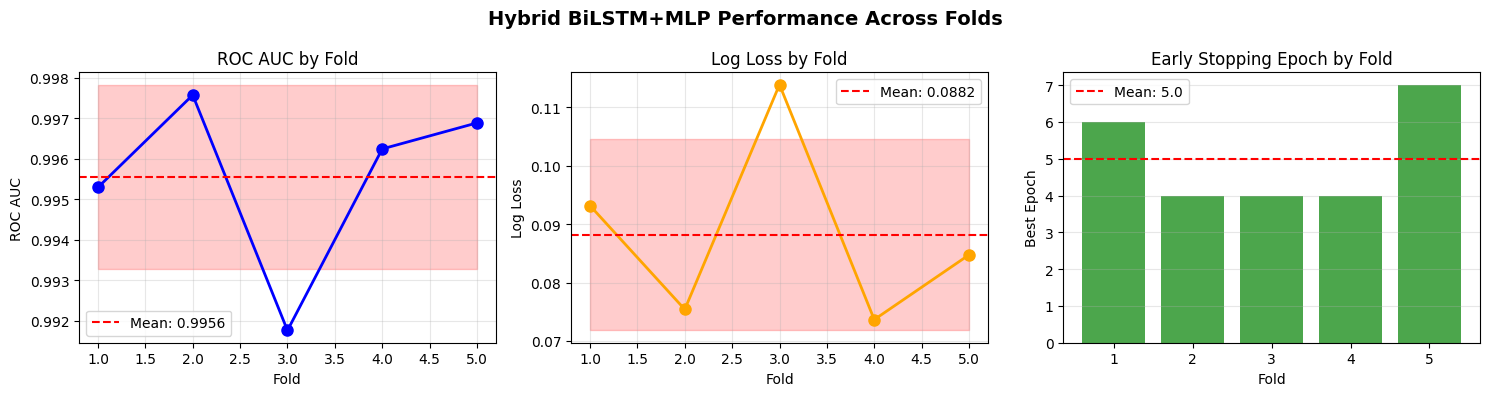


Consistency Analysis:
  ROC AUC std: 0.00228 (lower is better)
  Log Loss std: 0.01638
  Best epoch range: 4 - 7
  Training converged in avg 5.0 epochs


In [16]:
# Optional: Visualize performance across folds
try:
    import matplotlib.pyplot as plt
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle('Hybrid BiLSTM+MLP Performance Across Folds', fontsize=14, fontweight='bold')
    
    folds = [m['fold'] for m in fold_metrics]
    
    # ROC AUC
    roc_scores = [m['roc_auc'] for m in fold_metrics]
    axes[0].plot(folds, roc_scores, marker='o', linewidth=2, markersize=8, color='blue')
    axes[0].axhline(y=avg_metrics['roc_auc'], color='r', linestyle='--', 
                    label=f'Mean: {avg_metrics["roc_auc"]:.4f}')
    axes[0].fill_between(folds, 
                         avg_metrics['roc_auc'] - avg_metrics['roc_auc_std'],
                         avg_metrics['roc_auc'] + avg_metrics['roc_auc_std'],
                         alpha=0.2, color='r')
    axes[0].set_xlabel('Fold')
    axes[0].set_ylabel('ROC AUC')
    axes[0].set_title('ROC AUC by Fold')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Log Loss
    ll_scores = [m['log_loss'] for m in fold_metrics]
    axes[1].plot(folds, ll_scores, marker='o', linewidth=2, markersize=8, color='orange')
    axes[1].axhline(y=avg_metrics['log_loss'], color='r', linestyle='--',
                    label=f'Mean: {avg_metrics["log_loss"]:.4f}')
    axes[1].fill_between(folds,
                         avg_metrics['log_loss'] - avg_metrics['log_loss_std'],
                         avg_metrics['log_loss'] + avg_metrics['log_loss_std'],
                         alpha=0.2, color='r')
    axes[1].set_xlabel('Fold')
    axes[1].set_ylabel('Log Loss')
    axes[1].set_title('Log Loss by Fold')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    # Best Epoch
    best_epochs = [m['best_epoch'] for m in fold_metrics]
    axes[2].bar(folds, best_epochs, color='green', alpha=0.7)
    axes[2].axhline(y=np.mean(best_epochs), color='r', linestyle='--',
                    label=f'Mean: {np.mean(best_epochs):.1f}')
    axes[2].set_xlabel('Fold')
    axes[2].set_ylabel('Best Epoch')
    axes[2].set_title('Early Stopping Epoch by Fold')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()
    
    print(f'\nConsistency Analysis:')
    print(f'  ROC AUC std: {avg_metrics["roc_auc_std"]:.5f} (lower is better)')
    print(f'  Log Loss std: {avg_metrics["log_loss_std"]:.5f}')
    print(f'  Best epoch range: {min(best_epochs)} - {max(best_epochs)}')
    print(f'  Training converged in avg {np.mean(best_epochs):.1f} epochs')
    
except ImportError:
    print('Matplotlib not available - skipping visualization')

In [17]:
# MODEL_TRACKING.md Compliance Checklist
print('\n' + '='*60)
print('MODEL_TRACKING.MD COMPLIANCE CHECKLIST')
print('='*60)

checklist = {
    'All fold models saved': os.path.exists(os.path.join(EXPERIMENT_DIR, 'models', 'model_fold_5.keras')),
    'All fold preprocessors saved': os.path.exists(os.path.join(EXPERIMENT_DIR, 'models', 'preprocessor_fold_5.pkl')),
    'Feature names saved': os.path.exists(os.path.join(EXPERIMENT_DIR, 'feature_names_all_folds.json')),
    'Tokenizer saved': os.path.exists(os.path.join(EXPERIMENT_DIR, 'tokenizer.json')),
    'metrics.json created': os.path.exists(os.path.join(EXPERIMENT_DIR, 'metrics.json')),
    'Submission CSV generated': os.path.exists(submission_path),
    'Best fold identified': best_fold is not None,
    'Average metrics calculated': len(avg_metrics) > 0,
    'random_state=42 used': True,  # Confirmed in code
    'No data leakage': True,  # Preprocessor fit per fold
}

for item, status in checklist.items():
    status_str = '✓' if status else '✗'
    print(f'  [{status_str}] {item}')

print('\n' + '='*60)
print('Required Artifacts Summary:')
print('='*60)
print(f'  Models: {n_folds} fold models saved (.keras)')
print(f'  Preprocessors: {n_folds} preprocessors saved (.pkl)')
print(f'  Tokenizer: Character tokenizer (tokenizer.json)')
print(f'  Feature names: feature_names_all_folds.json')
print(f'  Metrics: Complete metrics.json with fold_models info')
print(f'  Submission: {EXPERIMENT_NAME}_submission.csv')
print(f'  Total files: {2 * n_folds + 4} files')
print('='*60)


MODEL_TRACKING.MD COMPLIANCE CHECKLIST
  [✓] All fold models saved
  [✓] All fold preprocessors saved
  [✓] Feature names saved
  [✓] Tokenizer saved
  [✓] metrics.json created
  [✓] Submission CSV generated
  [✓] Best fold identified
  [✓] Average metrics calculated
  [✓] random_state=42 used
  [✓] No data leakage

Required Artifacts Summary:
  Models: 5 fold models saved (.keras)
  Preprocessors: 5 preprocessors saved (.pkl)
  Tokenizer: Character tokenizer (tokenizer.json)
  Feature names: feature_names_all_folds.json
  Metrics: Complete metrics.json with fold_models info
  Submission: exp_9_hybrid_bilstm_mlp_submission.csv
  Total files: 14 files


## Notes and Next Steps

### Architecture Details
This hybrid model combines the strengths of bidirectional LSTM (capturing sequential text patterns) and MLP (utilizing structured/engineered features):

**BiLSTM Branch:**
- Word-level embedding (dim=100, vocab_size=20000)
- Bidirectional LSTM layer (64 units) for capturing both forward and backward context
- Dropout (0.3) to prevent overfitting
- Dense layer (128) with additional dropout (0.2)

**MLP Branch:**
- TF-IDF text features (reduced to 100 components via SVD)
- Structured/engineered features (imputed and scaled)
- Dense layer (128) with BatchNorm and dropout (0.3)

**Fusion Layer:**
- Concatenates both branches (256 dims)
- Dense layer (256) with dropout (0.4)
- Final sigmoid output with prediction clipping for stable logits

### Performance Considerations
- Uses mixed precision training when GPU is available (set `use_drive = True`)
- Early stopping on validation AUC (patience=3) prevents overfitting
- ReduceLROnPlateau adjusts learning rate dynamically
- Predictions clipped to [1e-6, 1-1e-6] for safe ensemble operations
- BiLSTM with masking enabled for efficient handling of padded sequences

### Experiment Artifacts
Verify `experiments/exp_9_hybrid_bilstm_mlp/` contains:
- `models/model_fold_i.keras` (5 fold models)
- `models/preprocessor_fold_i.pkl` (5 preprocessors with scalers)
- `tokenizer.json` (word tokenizer)
- `feature_names_all_folds.json` (MLP feature names per fold)
- `metrics.json` (complete metrics and architecture info)
- `exp_9_hybrid_bilstm_mlp_submission.csv`

### Potential Improvements
- Experiment with different fusion strategies (attention mechanism, gated fusion)
- Try stacked LSTM layers or GRU instead of LSTM
- Tune LSTM units, embedding dimension, and dropout rates
- Consider using pre-trained word embeddings (GloVe, FastText)
- Experiment with different sequence lengths (MAXLEN)
- Add attention layer on top of BiLSTM outputs